In [2]:
"""
Part 1: Data Loading & Initial Inspection
1. Import important libraries (pandas, numpy, matplotlib, seaborn, sklearn).
2. Load healthcare-dataset-stroke-data.csv into DataFrame df
3. Display first 5 rows using df.head()
4. Use df.info() to check data types, non-null values, memory usage
5. Use df.describe() for statistical summaries
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

df = pd.read_csv("healthcare-dataset-stroke-data.csv")
df


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [3]:
print(df.head(5))


      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  


In [4]:
print(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB
None


In [5]:
print(df.describe())

                 id          age  hypertension  heart_disease  \
count   5110.000000  5110.000000   5110.000000    5110.000000   
mean   36517.829354    43.226614      0.097456       0.054012   
std    21161.721625    22.612647      0.296607       0.226063   
min       67.000000     0.080000      0.000000       0.000000   
25%    17741.250000    25.000000      0.000000       0.000000   
50%    36932.000000    45.000000      0.000000       0.000000   
75%    54682.000000    61.000000      0.000000       0.000000   
max    72940.000000    82.000000      1.000000       1.000000   

       avg_glucose_level          bmi       stroke  
count        5110.000000  4909.000000  5110.000000  
mean          106.147677    28.893237     0.048728  
std            45.283560     7.854067     0.215320  
min            55.120000    10.300000     0.000000  
25%            77.245000    23.500000     0.000000  
50%            91.885000    28.100000     0.000000  
75%           114.090000    33.100000     0

<Axes: xlabel='stroke', ylabel='count'>

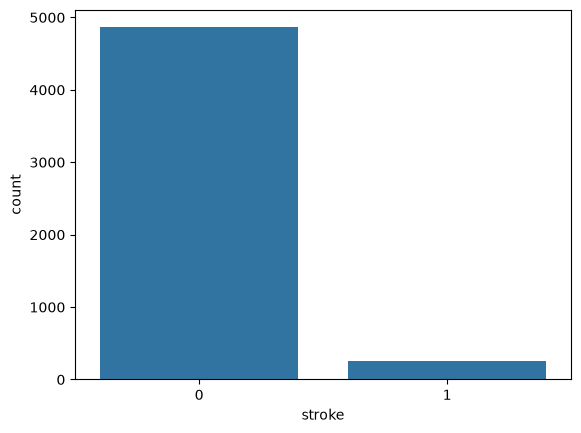

In [6]:
"""
Part 2: Exploratory Data Analysis & Visualization
1. Create countplot for stroke column (class distribution)
2. Create countplots with hue='stroke' for gender, work_type, smoking_status using subplots
3. Drop 'Other' gender record (only 1 exists)
4. Create histograms/KDE plots for age, avg_glucose_level, bmi using subplots
5. Create correlation heatmap using selected numerical features and stroke
"""
sns.countplot(data=df, x="stroke")

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')


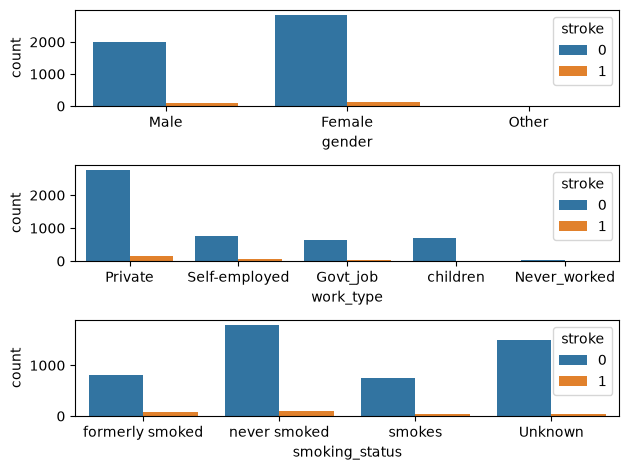

In [ ]:
fig, ax = plt.subplots(3,1) # 3 rows, 1 column
print(df.columns)
sns.countplot(data=df, x="gender", hue="stroke", ax=ax[0]) # ax= to indentify where to plot
sns.countplot(data=df, x="work_type", hue="stroke", ax=ax[1])
sns.countplot(data=df, x="smoking_status", hue="stroke", ax=ax[2])
fig.tight_layout()


In [8]:
rows_others = df[df["gender"] == "Other"] # extracting
df.drop(rows_others.index, inplace=True) # getting index of each row and removing inplace
print(df["gender"].unique()) # making sure

<StringArray>
['Male', 'Female']
Length: 2, dtype: str


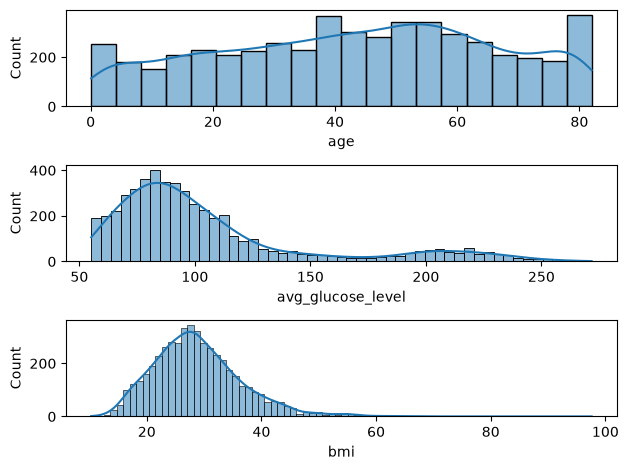

In [9]:
fig, ax = plt.subplots(3,1)
sns.histplot(data=df, kde=True,x="age", ax=ax[0])
sns.histplot(data=df, kde=True,x="avg_glucose_level", ax=ax[1])
sns.histplot(data=df, kde=True,x="bmi", ax=ax[2])

fig.tight_layout()

                     stroke
id                 0.006430
age                0.245239
hypertension       0.127891
heart_disease      0.134905
avg_glucose_level  0.131991
bmi                0.042341
stroke             1.000000


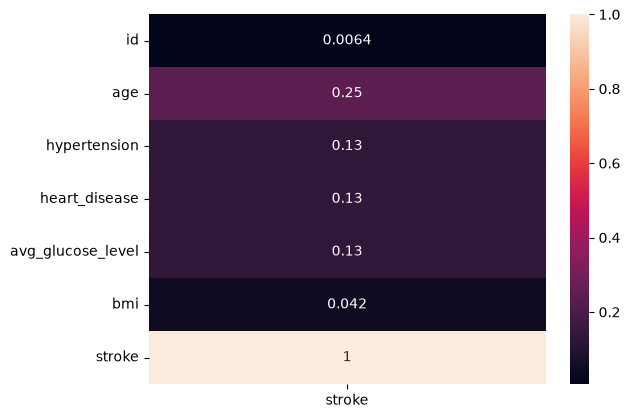

In [10]:
corr = df.corr(numeric_only= True)[["stroke"]] # with ref. to stroke column only
print(corr)
sns.heatmap(corr, annot=True)
plt.show()

In [11]:
"""
Part 3: Data Preprocessing (Cleaning)
1. Check for missing values using df.isnull().sum()
2. Fill bmi missing values using mean or median
3. Verify no missing values remain
4. Check for duplicates and remove them if any exist
5. Drop id column (no predictive power)
6. Create boxplot for avg_glucose_level to detect outliers and remove if needed
"""

'\nPart 3: Data Preprocessing (Cleaning)\n1. Check for missing values using df.isnull().sum()\n2. Fill bmi missing values using mean or median\n3. Verify no missing values remain\n4. Check for duplicates and remove them if any exist\n5. Drop id column (no predictive power)\n6. Create boxplot for avg_glucose_level to detect outliers and remove if needed\n'

In [12]:
print(df.isnull().sum())
bim_mean = df["bmi"].mean()
df["bmi"] = df["bmi"].fillna(bim_mean)
print(df.isnull().sum()) #verifying 



id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [13]:
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)

0


In [14]:
df.drop(columns="id", inplace=True)
print(df.columns)

Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')


In [28]:
df

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.50000,never smoked,1
6,Male,74.0,1,1,Yes,Private,Rural,70.09,27.40000,never smoked,1
7,Female,69.0,0,0,No,Private,Urban,94.39,22.80000,never smoked,1
8,Female,59.0,0,0,Yes,Private,Rural,76.15,28.89456,Unknown,1
9,Female,78.0,0,0,Yes,Private,Urban,58.57,24.20000,Unknown,1
...,...,...,...,...,...,...,...,...,...,...,...
5105,Female,80.0,1,0,Yes,Private,Urban,83.75,28.89456,never smoked,0
5106,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.00000,never smoked,0
5107,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.60000,never smoked,0
5108,Male,51.0,0,0,Yes,Private,Rural,166.29,25.60000,formerly smoked,0


In [31]:
pd.get_dummies(df)

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,ever_married_No,ever_married_Yes,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
2,80.0,0,1,105.92,32.50000,1,False,True,False,True,...,False,True,False,False,True,False,False,False,True,False
6,74.0,1,1,70.09,27.40000,1,False,True,False,True,...,False,True,False,False,True,False,False,False,True,False
7,69.0,0,0,94.39,22.80000,1,True,False,True,False,...,False,True,False,False,False,True,False,False,True,False
8,59.0,0,0,76.15,28.89456,1,True,False,False,True,...,False,True,False,False,True,False,True,False,False,False
9,78.0,0,0,58.57,24.20000,1,True,False,False,True,...,False,True,False,False,False,True,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5105,80.0,1,0,83.75,28.89456,0,True,False,False,True,...,False,True,False,False,False,True,False,False,True,False
5106,81.0,0,0,125.20,40.00000,0,True,False,False,True,...,False,False,True,False,False,True,False,False,True,False
5107,35.0,0,0,82.99,30.60000,0,True,False,False,True,...,False,False,True,False,True,False,False,False,True,False
5108,51.0,0,0,166.29,25.60000,0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,False


In [30]:
pd.get_dummies(df, drop_first=True)

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
2,80.0,0,1,105.92,32.50000,1,True,True,False,True,False,False,False,False,True,False
6,74.0,1,1,70.09,27.40000,1,True,True,False,True,False,False,False,False,True,False
7,69.0,0,0,94.39,22.80000,1,False,False,False,True,False,False,True,False,True,False
8,59.0,0,0,76.15,28.89456,1,False,True,False,True,False,False,False,False,False,False
9,78.0,0,0,58.57,24.20000,1,False,True,False,True,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5105,80.0,1,0,83.75,28.89456,0,False,True,False,True,False,False,True,False,True,False
5106,81.0,0,0,125.20,40.00000,0,False,True,False,False,True,False,True,False,True,False
5107,35.0,0,0,82.99,30.60000,0,False,True,False,False,True,False,False,False,True,False
5108,51.0,0,0,166.29,25.60000,0,True,True,False,True,False,False,False,True,False,False


In [ ]:
df

<Axes: xlabel='avg_glucose_level'>

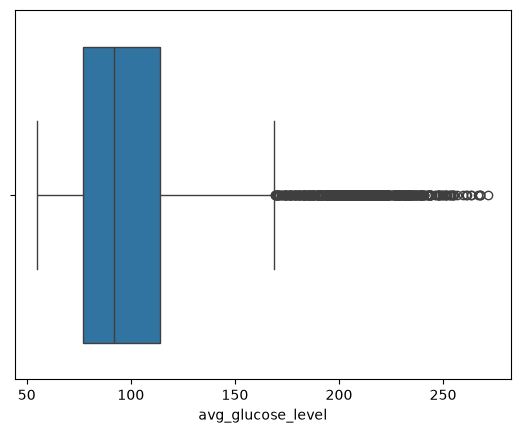

In [15]:
sns.boxplot(data=df, x="avg_glucose_level")


In [16]:
# Handling Outliers
print(df.shape)
q1 = df["avg_glucose_level"].quantile(0.25)
q3 = df["avg_glucose_level"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - (1.5*iqr)
upper_bound = q3 + (1.5*iqr)
df = df[(df["avg_glucose_level"] > lower_bound) & (df["avg_glucose_level"] < upper_bound)]

(5109, 11)


<Axes: xlabel='avg_glucose_level'>

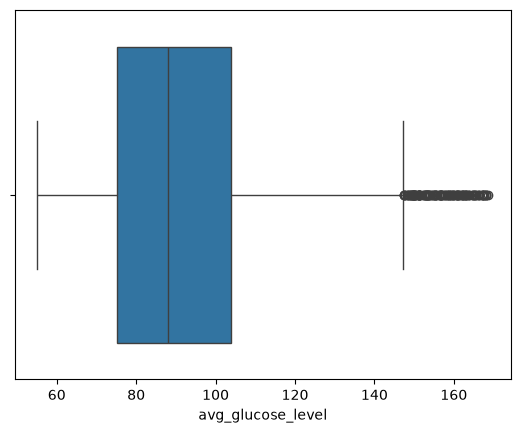

In [17]:
sns.boxplot(data=df, x="avg_glucose_level")


In [18]:
"""
Part 4: Data Splitting
1. Separate features X and target y
2. Use train_test_split() with 80/20 ratio and random_state=42
3. Verify shapes of X_train, X_test, y_train, y_test
"""
print(df.columns)
features = df.drop(columns="stroke")
target = df["stroke"]

Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')


In [19]:
from sklearn.model_selection import train_test_split
Xtrain , Xtest, ytrain, ytest = train_test_split(features, target, test_size=0.2, random_state=42)
print(Xtrain.shape)
print(Xtest.shape)
print(ytrain.shape)
print(ytest.shape)

(3585, 10)
(897, 10)
(3585,)
(897,)


In [20]:
print(df["gender"].unique())
print(df["smoking_status"].unique()) # use OrdinalEncoder , to describe levels of smoking
print(df["ever_married"].unique())
print(df["Residence_type"].unique())
# for others use LabelEncoder, as order does not matter

<StringArray>
['Male', 'Female']
Length: 2, dtype: str
<StringArray>
['never smoked', 'Unknown', 'smokes', 'formerly smoked']
Length: 4, dtype: str
<StringArray>
['Yes', 'No']
Length: 2, dtype: str
<StringArray>
['Rural', 'Urban']
Length: 2, dtype: str


In [ ]:
# Alternative

In [ ]:
"""
Part 5: Feature Transformation
1. Encode categorical variables: gender, work_type, smoking_status, ever_married, Residence_type
2. Use the suitable encoder with each column
3. Fit each encoder on training data only, then transform both train and test sets
"""
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

# i created an ecoder for each 1, because i got an error that couldn't be fixed 

gender_encoder = LabelEncoder()
married_encoder = LabelEncoder()
residence_encoder = LabelEncoder()
work_type_encoder = LabelEncoder()
ordinal_encoder = OrdinalEncoder(handle_unknown="use_encoded_value",
    unknown_value=-1)

In [22]:
# encoding training set
Xtrain["gender"] = gender_encoder.fit_transform(Xtrain["gender"])
Xtrain["ever_married"] = married_encoder.fit_transform(Xtrain["ever_married"])
Xtrain["Residence_type"] = residence_encoder.fit_transform(Xtrain["Residence_type"])
Xtrain["work_type"] = work_type_encoder.fit_transform(Xtrain["work_type"])
Xtrain[["smoking_status"]] = ordinal_encoder.fit_transform(Xtrain[["smoking_status"]])

In [23]:
# encoding test set
label_encoder = LabelEncoder()
Xtest["gender"] = gender_encoder.transform(Xtest["gender"])
Xtest["ever_married"] = married_encoder.transform(Xtest["ever_married"])
Xtest["Residence_type"] = residence_encoder.transform(Xtest["Residence_type"])
Xtest["work_type"] = work_type_encoder.transform(Xtest["work_type"])
Xtest[["smoking_status"]] = ordinal_encoder.transform(Xtest[["smoking_status"]])

In [24]:
"""
Part 6: Feature Scaling
1. Import StandardScaler or MinMaxScaler
2. Scale numerical features: age, avg_glucose_level, bmi
3. Fit scaler on training data only, then transform both train and test sets
"""
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numerical_columns = [
    "age",
    "avg_glucose_level",
    "bmi"
]
Xtrain[numerical_columns] = scaler.fit_transform(
    Xtrain[numerical_columns]
)
Xtest[numerical_columns] = scaler.transform(
    Xtest[numerical_columns]
)

In [25]:
"""
Part 7: Handling Class Imbalance
1. Check distribution of stroke
2. Apply oversampling/undersampling or SMOTE
3. Verify balanced distribution
"""
print(ytrain.value_counts())
# VERY unbalanced , to avoid lossing too much info => SMOTE oversampling

stroke
0    3451
1     134
Name: count, dtype: int64


In [26]:
from imblearn.over_sampling import SMOTE
smote_sampler = SMOTE()

Xtrain_Over_Sampled, ytrain_Over_sampled = smote_sampler.fit_resample(Xtrain, ytrain)

In [27]:
print(Xtrain_Over_Sampled.shape)
print(ytrain_Over_sampled.shape)
print(ytrain_Over_sampled.value_counts()) # VERIFIED

(6902, 10)
(6902,)
stroke
0    3451
1    3451
Name: count, dtype: int64
